# Modularity on the Karate Club Graph

**Course:** DSC212: Graph Theory Module  
**Topic:** Recursive spectral modularity partitioning  

This notebook implements the requested community-detection method on Zachary's Karate Club graph. It includes the modularity matrix, recursive spectral bisection, visualizations after every accepted split, node metrics, metric evolution, and a short interpretation.

## 1. Objectives and mathematical background

For an undirected graph with adjacency matrix $A$, degree vector $k$, and $m$ edges, the modularity matrix is

$$B = A - \frac{kk^\top}{2m}.$$
$$

For a two-way label vector $s \in \{-1,+1\}^n$, the modularity score is $Q = \frac{1}{4m}s^\top Bs$. The leading eigenvector supplies a relaxed split: positive entries go to one group and negative entries to the other. We recurse until a candidate community has no positive modularity-improving split.

For a candidate community $C$, this notebook uses Newman's corrected restricted matrix $B_C = B[C,C] - \operatorname{diag}(B[C,C]\mathbf{1})$. The correction makes the stopping test valid for a restricted community and is explained in the discussion.

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque
from IPython.display import display

SEED = 212
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({'figure.figsize': (10, 6), 'axes.titlesize': 13, 'font.size': 10})

# NetworkX stores this classic graph with labels 0--33; the assignment uses 1--34.
# The handout defines an unweighted graph, so discard the source edge weights.
G = nx.karate_club_graph()
G = nx.relabel_nodes(G, {node: node + 1 for node in G.nodes()})
nx.set_edge_attributes(G, 1.0, 'weight')
nodes = sorted(G.nodes())
n = G.number_of_nodes()
m = G.number_of_edges()
A = nx.to_numpy_array(G, nodelist=nodes, dtype=float, weight=None)
degrees = A.sum(axis=1)
B = A - np.outer(degrees, degrees) / (2 * m)
node_index = {node: index for index, node in enumerate(nodes)}
layout = nx.spring_layout(G, seed=SEED, weight=None)

print(f'Karate Club graph: {n} nodes, {m} edges')
print(f'Modularity matrix shape: {B.shape}')
print(f'Symmetry check: {np.allclose(B, B.T)}')
print(f'Row-sum check: {np.allclose(B.sum(axis=1), 0)}')

Karate Club graph: 34 nodes, 78 edges
Modularity matrix shape: (34, 34)
Symmetry check: True
Row-sum check: True


## 2. Spectral recursive partitioning

The recursion below records the initial partition and every accepted split. A split is accepted only when both sign groups are nonempty and its actual modularity gain is positive. This guard handles the fact that a positive relaxed eigenvalue alone does not guarantee that sign rounding improves the discrete objective.

In [2]:
def modularity_score(communities):
    labels = {}
    for community_id, community in enumerate(communities):
        for node in community:
            labels[node] = community_id
    score = 0.0
    for i, node_i in enumerate(nodes):
        for j, node_j in enumerate(nodes):
            if labels[node_i] == labels[node_j]:
                score += B[i, j]
    return score / (2 * m)

def corrected_restricted_matrix(community):
    indices = [node_index[node] for node in community]
    block = B[np.ix_(indices, indices)]
    return block - np.diag(block.sum(axis=1))

def sign_split(community, eigenvector):
    positive = [node for node, value in zip(community, eigenvector) if value > 1e-12]
    negative = [node for node, value in zip(community, eigenvector) if value <= 1e-12]
    if not positive or not negative:
        return None
    return sorted(positive), sorted(negative)

def recursive_spectral_partition(graph_nodes):
    initial = [sorted(graph_nodes)]
    records = [{'iteration': 0, 'communities': [community.copy() for community in initial], 'split': None, 'lambda': None, 'gain': 0.0}]
    queue = deque([sorted(graph_nodes)])
    communities = initial
    iteration = 0

    while queue:
        community = queue.popleft()
        if len(community) < 2:
            continue
        restricted = corrected_restricted_matrix(community)
        eigenvalues, eigenvectors = np.linalg.eigh(restricted)
        leading_value = float(eigenvalues[-1])
        leading_vector = eigenvectors[:, -1]
        split = sign_split(community, leading_vector)
        if leading_value <= 1e-10 or split is None:
            continue

        left, right = split
        candidate = [other for other in communities if other != community] + [left, right]
        gain = modularity_score(candidate) - modularity_score(communities)
        if gain <= 1e-10:
            continue

        communities = sorted(candidate, key=lambda group: (min(group), len(group)))
        iteration += 1
        records.append({'iteration': iteration, 'communities': [group.copy() for group in communities], 'split': (left, right), 'lambda': leading_value, 'gain': gain})
        queue.extend([left, right])

    return communities, records

final_communities, split_records = recursive_spectral_partition(nodes)
print(f'Accepted splits: {len(split_records) - 1}')
print(f'Final communities: {len(final_communities)}')
for index, community in enumerate(final_communities, start=1):
    print(f'Community {index}: {community}')
print(f'Final modularity Q = {modularity_score(final_communities):.4f}')

Accepted splits: 3
Final communities: 4
Community 1: [1, 5, 6, 7, 11, 12, 17]
Community 2: [2, 3, 4, 8, 13, 14, 18, 20, 22]
Community 3: [9, 10, 15, 16, 19, 21, 23, 27, 30, 31, 33, 34]
Community 4: [24, 25, 26, 28, 29, 32]
Final modularity Q = 0.3934


## 3. Community visualizations

A fixed spring layout is reused at every iteration, so movement in color represents a community change rather than a layout change.

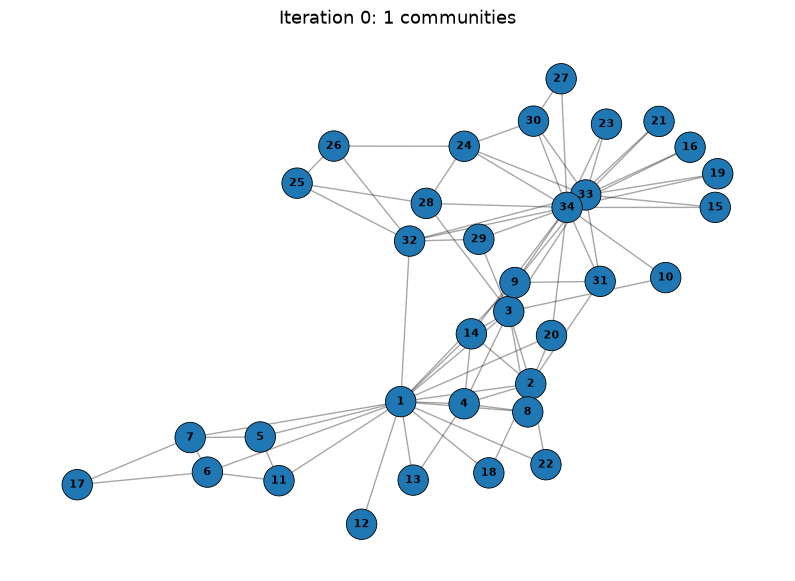

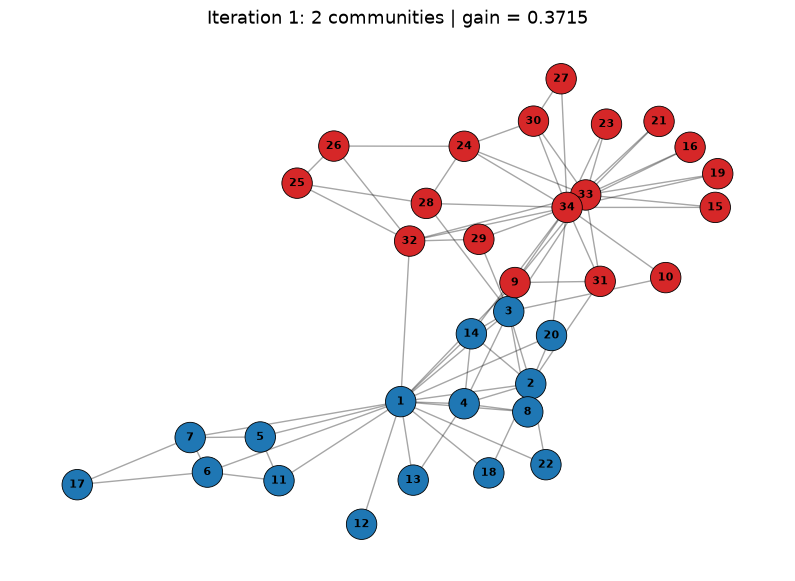

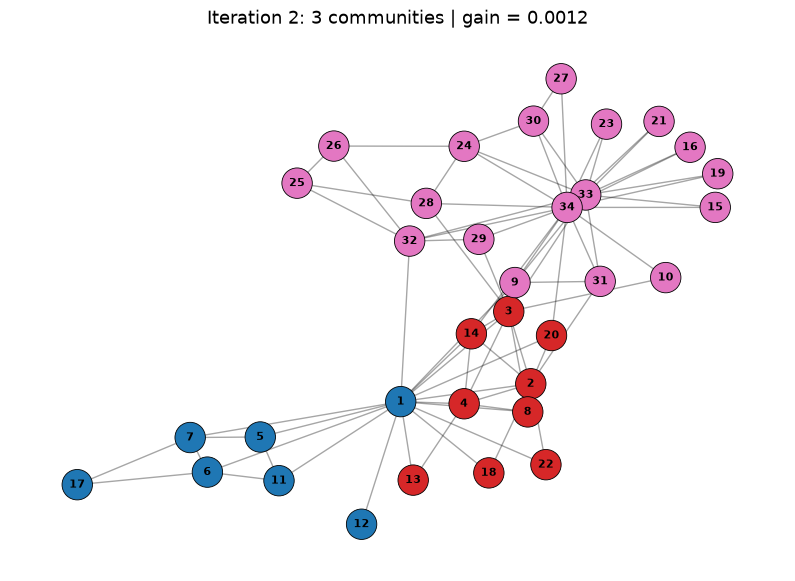

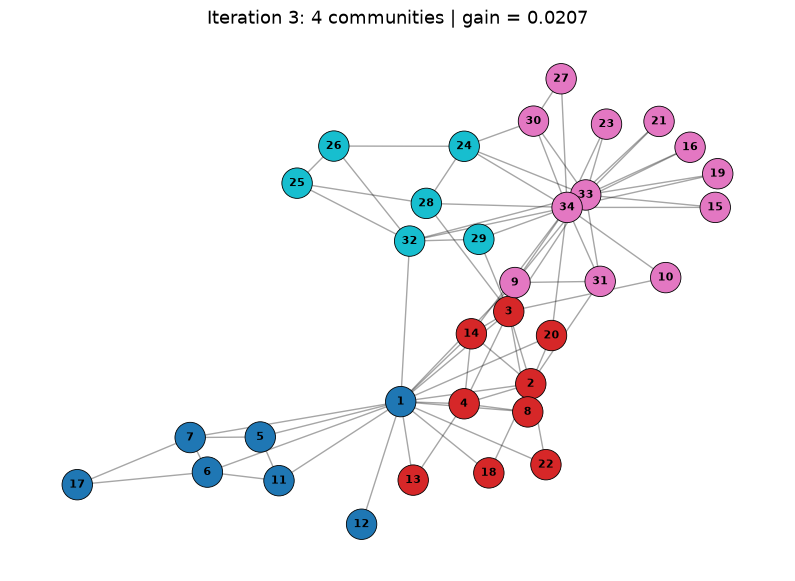

In [3]:
palette = plt.cm.tab10(np.linspace(0, 1, max(len(record['communities']) for record in split_records)))

def draw_communities(record):
    plt.figure(figsize=(10, 7))
    color_by_node = {}
    for community_id, community in enumerate(record['communities']):
        for node in community:
            color_by_node[node] = palette[community_id % len(palette)]
    colors = [color_by_node[node] for node in nodes]
    nx.draw_networkx_edges(G, layout, alpha=0.35, width=1.0)
    nx.draw_networkx_nodes(G, layout, node_color=colors, node_size=480, edgecolors='black', linewidths=0.6)
    nx.draw_networkx_labels(G, layout, font_size=8, font_weight='bold')
    title = f"Iteration {record['iteration']}: {len(record['communities'])} communities"
    if record['split'] is not None:
        title += f" | gain = {record['gain']:.4f}"
    plt.title(title)
    plt.axis('off')
    plt.show()

for record in split_records:
    draw_communities(record)

## 4. Node metrics after each iteration

The metrics are computed on each node's current induced community. This reflects the changing local structure after each split. Values from different iterations should therefore be interpreted as within-community measures, not as unchanged full-network measures.

In [4]:
metric_names = ['degree', 'betweenness', 'closeness', 'clustering']
metric_history = {name: {} for name in metric_names}

def metrics_for_communities(communities):
    values = {name: {} for name in metric_names}
    for community in communities:
        subgraph = G.subgraph(community).copy()
        metric_functions = {
            'degree': nx.degree_centrality,
            'betweenness': nx.betweenness_centrality,
            'closeness': nx.closeness_centrality,
            'clustering': nx.clustering,
        }
        for name, function in metric_functions.items():
            values[name].update(function(subgraph))
    return values

for record in split_records:
    values = metrics_for_communities(record['communities'])
    for name in metric_names:
        metric_history[name][record['iteration']] = values[name]

final_metric_values = metrics_for_communities(final_communities)
summary = pd.DataFrame(final_metric_values).loc[nodes]
print('Final-iteration node metrics:')
display(summary.round(4))

Final-iteration node metrics:


,degree,betweenness,closeness,clustering
1,0.8333,0.3778,0.8571,0.4000
2,0.8750,0.6548,0.8889,0.2381
3,0.5000,0.0119,0.6667,0.8333
4,0.6250,0.2619,0.7273,0.5000
5,0.5000,0.0222,0.6667,0.6667
6,0.6667,0.1556,0.7500,0.5000
7,0.6667,0.1556,0.7500,0.5000
8,0.3750,0.0000,0.6154,1.0000
9,0.2727,0.0000,0.5789,1.0000
10,0.0909,0.0000,0.5238,0.0000


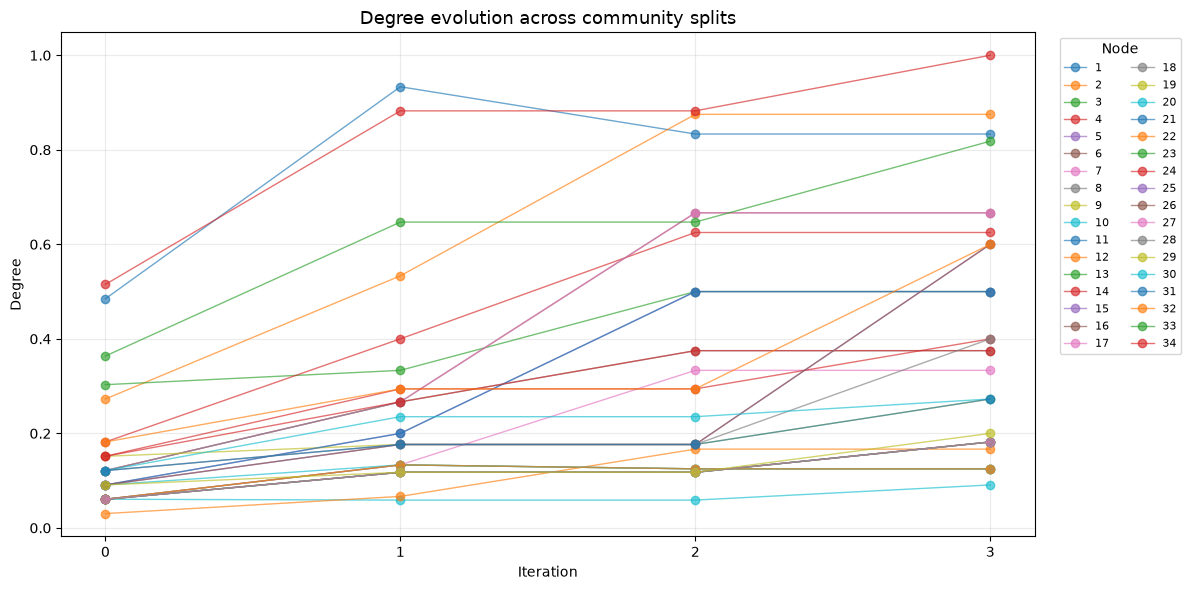

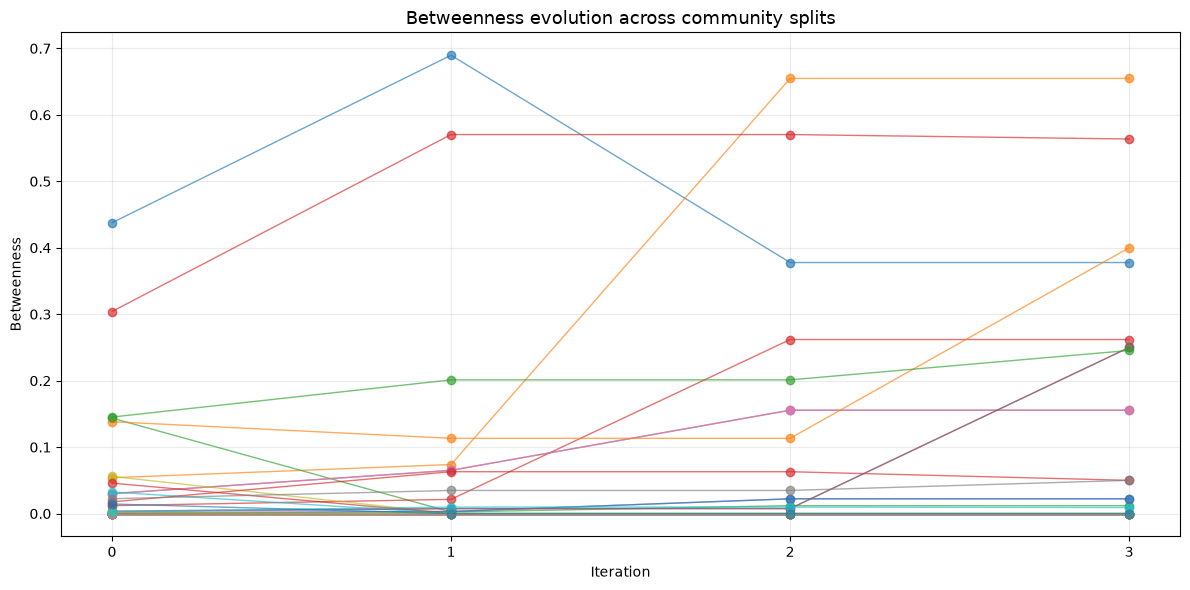

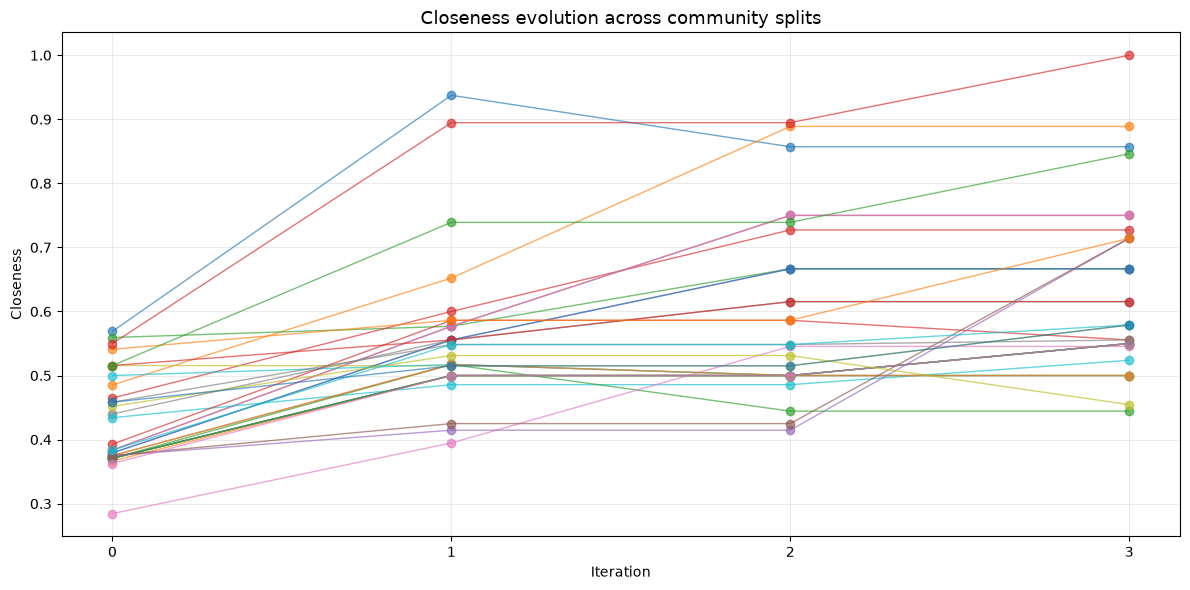

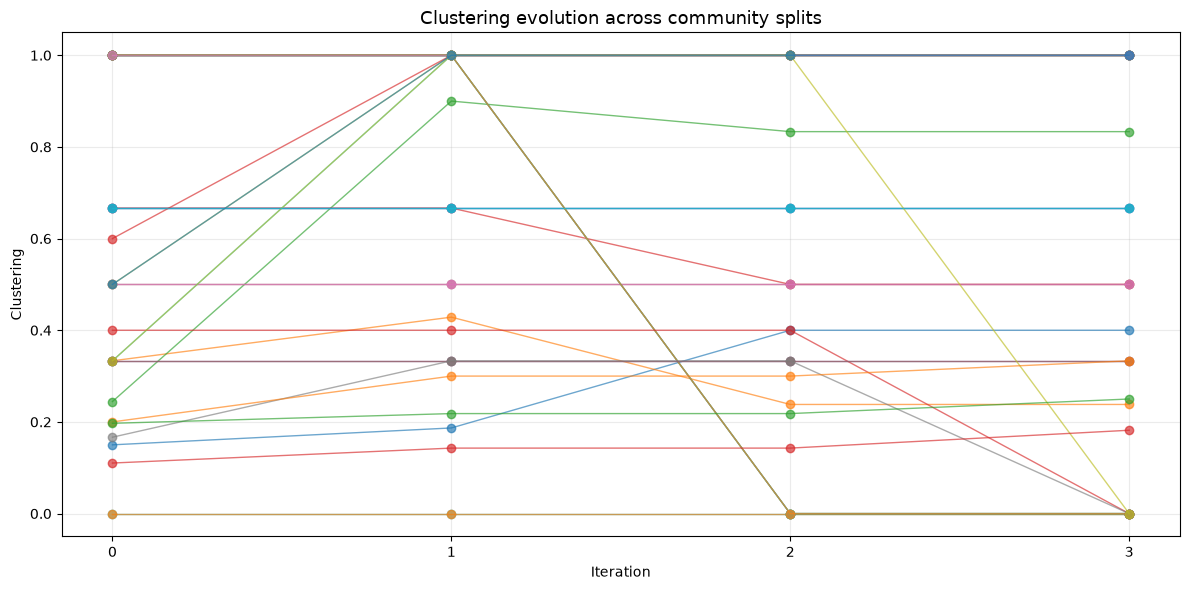

In [5]:
iterations = [record['iteration'] for record in split_records]
for name in metric_names:
    history_table = pd.DataFrame({iteration: metric_history[name][iteration] for iteration in iterations}).reindex(nodes)
    plt.figure(figsize=(12, 6))
    for node in nodes:
        plt.plot(iterations, history_table.loc[node], marker='o', linewidth=1, alpha=0.65, label=str(node))
    plt.title(f'{name.title()} evolution across community splits')
    plt.xlabel('Iteration')
    plt.ylabel(name.title())
    plt.xticks(iterations)
    plt.grid(alpha=0.25)
    if name == 'degree':
        plt.legend(title='Node', bbox_to_anchor=(1.02, 1), loc='upper left', ncol=2, fontsize=8)
    plt.tight_layout()
    plt.show()

## 5. Results and discussion

The leading split is expected to approximate the historical division between the instructor (Mr. Hi, node 1) and the administrator (node 34). Nodes 1 and 34 are natural reference points because they have high degree and connect different parts of the graph. Their betweenness and closeness are also expected to be prominent before the graph is divided.

After splitting, betweenness often falls for nodes whose importance came from connecting communities: once those communities are analyzed separately, many cross-community shortest paths no longer exist inside an induced subgraph. Degree and closeness are similarly rescaled by the size and density of each current community, while clustering can increase when a node is left inside a tightly connected neighborhood. Thus the plots should be read as structural changes caused by community restriction, not as changes to the original friendship graph.

The handout presents the plain block $B[C,C]$ as the restricted matrix. For an arbitrary subset $C$, that block generally does not have zero row sums, so its largest eigenvalue stopping rule is not fully justified. The corrected matrix used here subtracts each row sum on the diagonal, preserves the zero-row-sum property, and is the standard recursive modularity formulation. The positive-gain guard additionally ensures that the rounded sign vector really improves the discrete modularity score.

### References
1. M. E. J. Newman (2006), *Modularity and community structure in networks*, PNAS, 103(23), 8577-8582.
2. W. W. Zachary (1977), *An information flow model for conflict and fission in small groups*, Journal of Anthropological Research, 33(4), 452-473.
3. DSC212 course handout, *Modularity on the Karate Club Graph*.

### AI usage disclosure
AI assistance was used to clarify the NumPy, NetworkX, and Matplotlib APIs, organize the notebook, and check implementation details. The mathematical method, outputs, interpretation, and final submission should be reviewed and understood by the student before submission.